## Figure 1.2 — Multi-model frequency dipole / $\hat{\boldsymbol d}_{\mathrm{prior}}$

Plot $\hat{\boldsymbol d}_{\mathrm{prior}}$ in the PCA plane of the output embedding
across selected models. Configure `corpus_choice` (`pile` / `code` / `code - pile`)
and `token_mode` (`all` / `leading_space` / `subword` / `both`). With `both`, PCA and
coloring use the full corpus; arrows show full-word (black) and sub-word (red).


In [2]:
import os
from pathlib import Path


# A stale HF_TOKEN env var shadows the working `hf auth login` credential and
# breaks gated datasets (e.g. bigcode/starcoderdata). Prefer the on-disk token.
_hf_login = Path.home() / ".cache" / "huggingface" / "token"
if _hf_login.exists():
    os.environ["HF_TOKEN"] = _hf_login.read_text().strip()
    os.environ["HUGGING_FACE_HUB_TOKEN"] = os.environ["HF_TOKEN"]

import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Self-contained layout: direction_of_prior/{scripts, data, notebook_plotters}
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebook_plotters" else cwd
SCRIPTS_DIR = ROOT / "scripts"
DATA_DIR = ROOT / "data"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import utils
import pile_token_stats
import dipole_utils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [3]:
#######################################################
##### Hyper-parameters for calculating token frequency
#######################################################
p_zipf_from_pile = True  # False -> synthetic Zipf; True -> stream corpus below
zipf_alpha = 1.0  # used only when p_zipf_from_pile is False

# Swap the empirical unigram corpus here. Presets:
#   "pile"       — general text (monology Pile stream; default elsewhere)
#   "code"       — coding-training proxy: StarCoder Python slice
#   "code - pile"— code unigram on tokens most distinctive vs Pile
#                  (top vocab_coverage by log(p_code / p_pile))
# Code presets need BigCode dataset access on Hugging Face.
# corpus_choice = "code - pile"  # "pile" | "code" | "code - pile"
corpus_choice = "pile"
vocab_coverage = 0.7
contrast_epsilon = 1e-12  # Laplace floor for the code-vs-Pile log-ratio

# Token-subset mode for fitting d_prior:
#   "all"           — current pipeline (all coverage tokens)
#   "leading_space" — only tokens that begin a whitespace-delimited word ("full word")
#   "subword"       — only tokens without a leading space
#   "both"          — two arrows (full-word black, sub-word red); PCA/color from all tokens
token_mode = "all"  # "all" | "leading_space" | "subword" | "both"
token_mode = "both"

CORPUS_PRESETS = {
    "pile": {
        "kind": "empirical",
        "dataset_name": "monology/pile-uncopyrighted",
        "dataset_config": None,
        "data_dir": None,
        "split": "train",
        "text_column": "text",
    },
    # Python-only StarCoder training data: representative later-stage code mix
    # with inline file text (unlike Stack-Edu IDs, which need S3 fetches).
    "code": {
        "kind": "empirical",
        "dataset_name": "bigcode/starcoderdata",
        "dataset_config": None,
        "data_dir": "python",
        "split": "train",
        "text_column": "content",
    },
    # Contrastive support: keep tokens with largest log(p_code/p_pile), then
    # renormalize p_code on that support. Alias: "code-pile".
    "code - pile": {
        "kind": "contrastive",
        "foreground": "code",
        "background": "pile",
    },
}
CORPUS_PRESETS["code-pile"] = CORPUS_PRESETS["code - pile"]

if corpus_choice not in CORPUS_PRESETS:
    raise KeyError(
        f"Unknown corpus_choice={corpus_choice!r}; "
        f"expected one of {sorted(k for k in CORPUS_PRESETS if k != 'code-pile')}"
    )
_corpus = CORPUS_PRESETS[corpus_choice]
corpus_kind = _corpus["kind"]
if corpus_kind == "empirical":
    corpus_name = _corpus["dataset_name"]
    corpus_config = _corpus["dataset_config"]
    corpus_data_dir = _corpus["data_dir"]
    corpus_split = _corpus["split"]
    corpus_text_column = _corpus["text_column"]
    print(
        f"corpus_choice={corpus_choice!r} -> {corpus_name}"
        + (f" data_dir={corpus_data_dir!r}" if corpus_data_dir else "")
        + f" text_column={corpus_text_column!r}"
    )
else:
    fg_key = _corpus["foreground"]
    bg_key = _corpus["background"]
    corpus_name = f"contrast:{fg_key}-vs-{bg_key}"
    corpus_config = None
    corpus_data_dir = None
    corpus_split = "train"
    corpus_text_column = None
    print(
        f"corpus_choice={corpus_choice!r} -> contrastive "
        f"foreground={fg_key!r}, background={bg_key!r}, "
        f"score=log((p_fg+eps)/(p_bg+eps)), eps={contrast_epsilon:g}"
    )

TOKEN_MODE_CHOICES = ("all", "leading_space", "subword", "both")
if token_mode not in TOKEN_MODE_CHOICES:
    raise KeyError(f"Unknown token_mode={token_mode!r}; expected one of {TOKEN_MODE_CHOICES}")
print(f"token_mode={token_mode!r}")

#######################################################
##### Hyper-parameters for calculating frequency dipole
#######################################################
# dipole_method = "moment"  # "moment" or "optimal_prior"
dipole_method = "optimal_prior"

#######################################################
##### Multi-model selection
#######################################################
grid_models = [
    # "meta-llama/Llama-3.2-1B",
    # "meta-llama/Llama-3.2-3B",
    "meta-llama/Llama-3.1-8B",
    "meta-llama/Llama-3.1-70B",
    "meta-llama/Llama-3.1-405B",
    # "google/gemma-3-1b-pt",
    # "google/gemma-3-4b-pt",
    # "Qwen/Qwen2.5-1.5B",
    # "Qwen/Qwen2.5-3B",
    # "EleutherAI/pythia-410M",
    # "EleutherAI/pythia-1B",
    # "EleutherAI/pythia-1.4B",
]

fig2_cache_dir = DATA_DIR / "fig2_cache"
pythia_prior_cache_dir = DATA_DIR / "fig6_lambda_training_dynamics"
grid_pca_cache_dir = DATA_DIR / "fig1_multimodel_pca"
grid_pca_cache_dir.mkdir(parents=True, exist_ok=True)
fig2_num_passages = 200
pythia_num_passages = 300
pca_random_seed = 0
pca_sample_size = 8_000
projection_batch_size = 1_024


corpus_choice='pile' -> monology/pile-uncopyrighted text_column='text'
token_mode='both'


### Multi-model $\hat{\boldsymbol d}_{\mathrm{prior}}$ geometry


fig saved at plot_export/appdx_dual_prior_multimodel.png


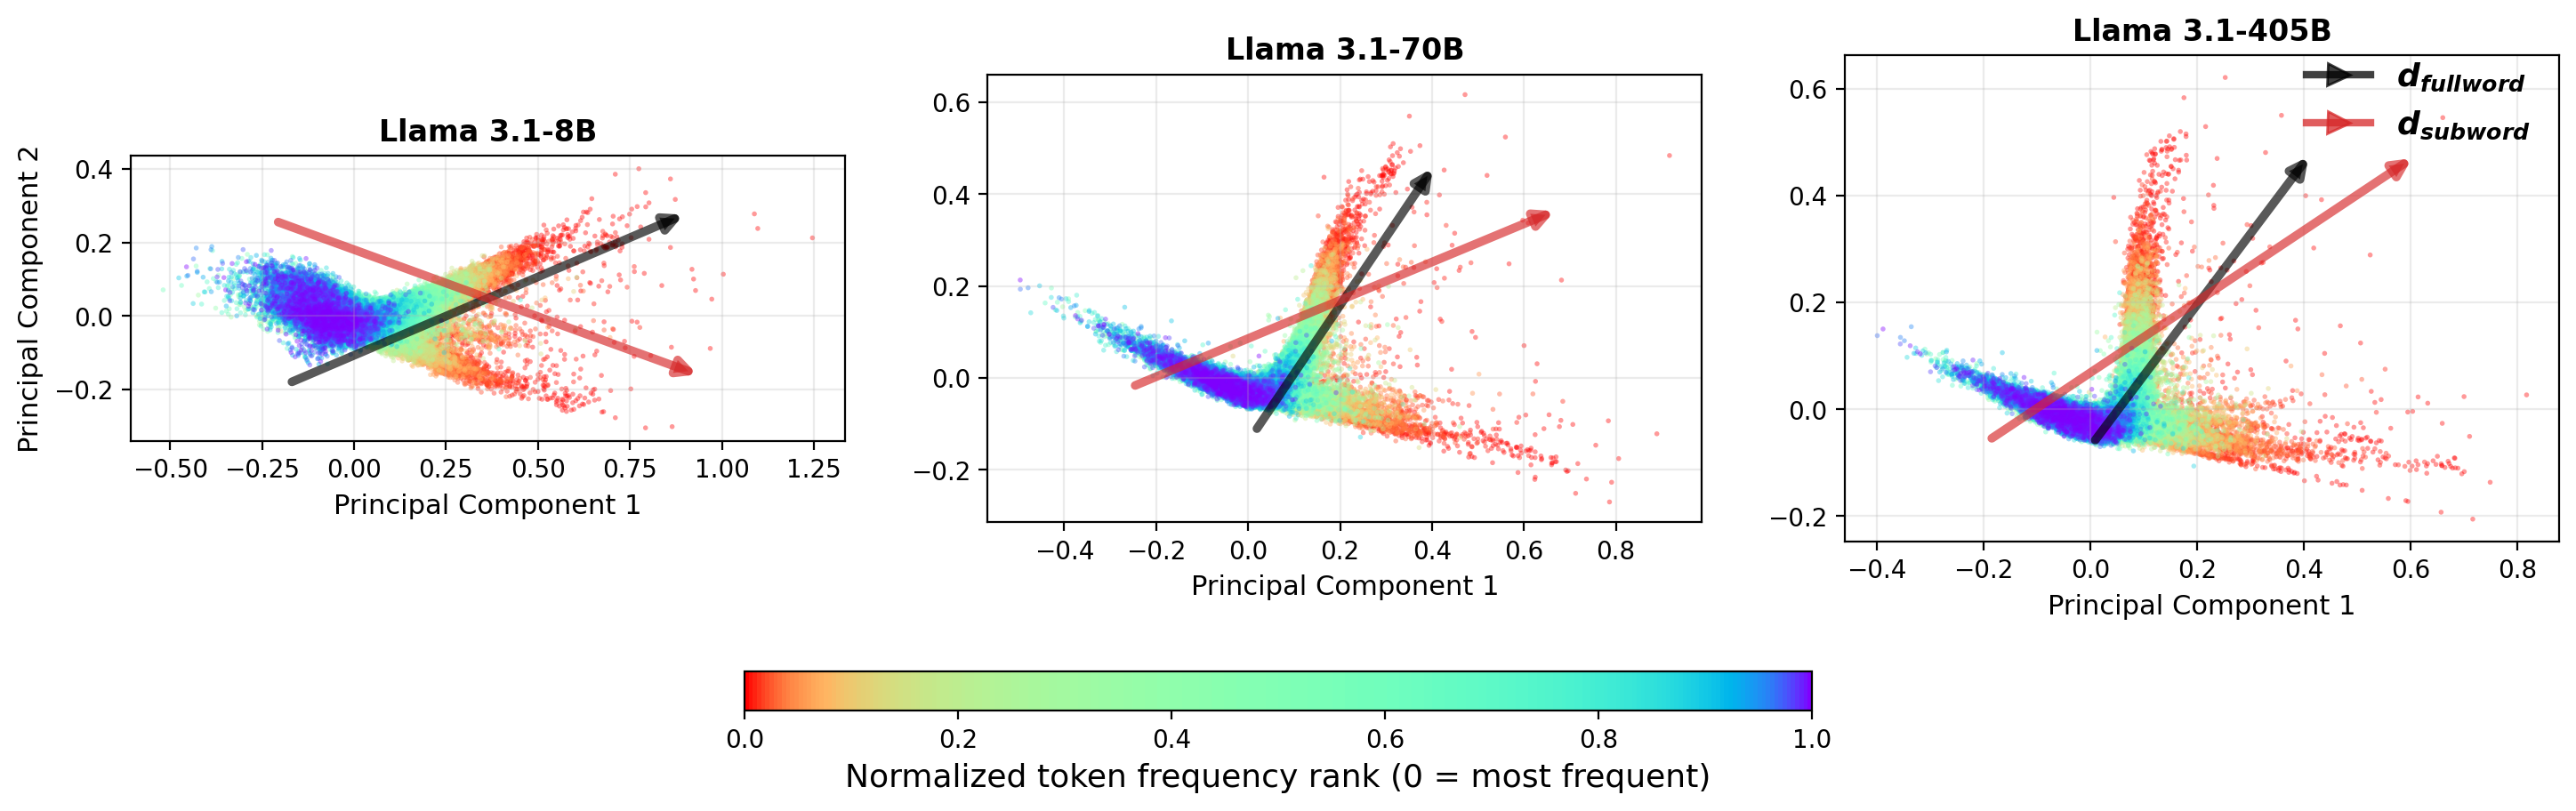

In [4]:
# Multi-model output-embedding geometry for every model in `grid_models`.
# Reuses cached W_out from Fig. 2 / Fig. 6, but refits d_prior at the coverage
# and corpus configured above (Pile by default).
import re
from importlib import reload

reload(pile_token_stats)
reload(utils)

pythia_grid_num_passages = pythia_num_passages
grid_num_passages = fig2_num_passages


def grid_model_tag(name):
    return name.replace("/", "__")


def grid_model_label(name):
    return (
        name.split("/", 1)[-1]
        .replace("Llama-", "Llama ")
        .replace("gemma-", "Gemma ")
        .replace("Qwen", "Qwen ")
        .replace("pythia-", "Pythia ")
        .replace("-pt", "")
    )


def latest_pythia_prior_path(name):
    """(step, path) of the latest cached fig6 prior fit for a Pythia model."""
    short = name.split("/")[-1]
    candidates = sorted(
        (int(re.search(r"_step(\d+)_", path.name).group(1)), path)
        for path in pythia_prior_cache_dir.glob(
            f"prior_{short}_step*_N{pythia_grid_num_passages}_T300.npz"
        )
    )
    if not candidates:
        raise FileNotFoundError(f"No Pythia checkpoint prior fits for {name}.")
    return candidates[-1]


def cache_pythia_w_out(name, step, destination):
    """Extract W_out from the locally cached HF checkpoint and save float32."""
    print(f"Extracting W_out: {grid_model_label(name)} step {step:,}")
    checkpoint = AutoModelForCausalLM.from_pretrained(
        name, revision=f"step{step}", dtype="auto",
    )
    w_out_np = (
        checkpoint.get_output_embeddings().weight.detach().float().cpu().numpy()
    )
    del checkpoint
    partial = destination.with_name(destination.stem + ".partial.npy")
    np.save(partial, w_out_np)
    os.replace(partial, destination)
    print(f"  cached -> {destination.name} ({destination.stat().st_size / 2**20:.0f} MiB)")


def exact_embedding_mean(w_out_memmap, batch_size=2_048):
    total = np.zeros(w_out_memmap.shape[1], dtype=np.float64)
    for start in range(0, w_out_memmap.shape[0], batch_size):
        total += np.asarray(w_out_memmap[start:start + batch_size], dtype=np.float64).sum(axis=0)
    return (total / w_out_memmap.shape[0]).astype(np.float32)


def sampled_pca_basis(w_out_memmap, mean, direction, sample_size, seed):
    """Fit two centered PCs from a deterministic vocabulary sample."""
    rng = np.random.default_rng(seed)
    sample_size = min(int(sample_size), w_out_memmap.shape[0])
    sample_ids = rng.choice(w_out_memmap.shape[0], size=sample_size, replace=False)
    sample = np.asarray(w_out_memmap[sample_ids], dtype=np.float32) - mean
    pca_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(seed)
    sample_tensor = torch.from_numpy(sample).to(pca_device)
    _, _, basis = torch.pca_lowrank(sample_tensor, q=min(4, sample_size), center=False)
    basis = basis[:, :2].float().cpu().numpy()
    del sample_tensor
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # PCA signs are arbitrary. Orient each axis so the prior direction has a
    # nonnegative component, making panels visually consistent.
    direction_projection = np.asarray(direction, dtype=np.float32) @ basis
    signs = np.where(direction_projection < 0, -1.0, 1.0).astype(np.float32)
    return basis * signs


def project_embedding_rows(w_out_memmap, token_ids, mean, basis, batch_size):
    """Project selected vocabulary rows in batches without materializing W_out."""
    result = np.empty((len(token_ids), 2), dtype=np.float32)
    pca_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    basis_tensor = torch.from_numpy(np.asarray(basis, dtype=np.float32)).to(pca_device)
    mean_tensor = torch.from_numpy(np.asarray(mean, dtype=np.float32)).to(pca_device)
    for start in range(0, len(token_ids), batch_size):
        stop = min(start + batch_size, len(token_ids))
        block = np.asarray(w_out_memmap[token_ids[start:stop]], dtype=np.float32)
        block_tensor = torch.from_numpy(block).to(pca_device)
        result[start:stop] = ((block_tensor - mean_tensor) @ basis_tensor).cpu().numpy()
        del block_tensor
    del basis_tensor, mean_tensor
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


def _safe_path_tag(text):
    return str(text).replace("/", "__").replace("\\", "__")


def _preset_cache_tag(preset):
    tag = preset["dataset_name"].replace("/", "__")
    if preset.get("dataset_config"):
        tag = f"{tag}__{_safe_path_tag(preset['dataset_config'])}"
    if preset.get("data_dir"):
        tag = f"{tag}__{_safe_path_tag(preset['data_dir'])}"
    return tag


def corpus_cache_tag():
    if corpus_kind == "contrastive":
        fg = CORPUS_PRESETS[_corpus["foreground"]]
        bg = CORPUS_PRESETS[_corpus["background"]]
        eps_tag = f"{contrast_epsilon:g}".replace(".", "p").replace("-", "m")
        return (
            f"contrast__{_preset_cache_tag(fg)}__vs__{_preset_cache_tag(bg)}"
            f"__eps{eps_tag}"
        )
    tag = corpus_name.replace("/", "__")
    if corpus_config:
        tag = f"{tag}__{_safe_path_tag(corpus_config)}"
    if corpus_data_dir:
        tag = f"{tag}__{_safe_path_tag(corpus_data_dir)}"
    return tag


def _empirical_cache_path(tokenizer_tag, preset):
    return DATA_DIR / "token_stats" / (
        f"{tokenizer_tag}__{_preset_cache_tag(preset)}__token_probs.npz"
    )


def _ensure_empirical_counts(tokenizer, vocab_size, tokenizer_tag, preset_key):
    """Stream/load a base corpus cache and return its raw count vector."""
    preset = CORPUS_PRESETS[preset_key]
    cache_path = _empirical_cache_path(tokenizer_tag, preset)
    if cache_path.exists():
        with np.load(cache_path) as cached:
            cached_cov = float(cached["coverage"]) if "coverage" in cached.files else float("nan")
            cached_tokens = int(cached["n_tokens"]) if "n_tokens" in cached.files else -1
        print(
            f"[{preset_key}] token-stats cache: {cache_path.name} "
            f"(n_tokens={cached_tokens:,}, cached_coverage={cached_cov:.1%}; "
            f"requested={vocab_coverage:.1%})"
        )
    else:
        print(f"[{preset_key}] token-stats cache miss -> streaming {cache_path.name}")
    # Side effect: refresh/resume the count cache up to the requested coverage.
    pile_token_stats.empirical_token_prob(
        tokenizer,
        vocab_size=vocab_size,
        coverage=vocab_coverage,
        dataset_name=preset["dataset_name"],
        dataset_config=preset["dataset_config"],
        data_dir=preset["data_dir"],
        split=preset["split"],
        text_column=preset["text_column"],
        cache_path=cache_path,
        report_every=1_000,
    )
    return pile_token_stats.load_cached_token_counts(cache_path)


def token_probabilities(tokenizer, vocab_size):
    """Unigram probs from the configured corpus, or a synthetic Zipf fallback.

    Empirical presets cache counts under data/token_stats/. The contrastive
    "code - pile" preset reuses the code and pile caches, keeps the top
    vocab_coverage tokens by log((p_code+eps)/(p_pile+eps)), and renormalizes
    p_code on that support.
    """
    if not p_zipf_from_pile:
        ranks = np.arange(1, vocab_size + 1, dtype=np.float64)
        return 1.0 / ranks ** zipf_alpha

    tokenizer_tag = pile_token_stats.tokenizer_cache_tag(tokenizer, vocab_size=vocab_size)

    if corpus_kind == "contrastive":
        fg_key = _corpus["foreground"]
        bg_key = _corpus["background"]
        fg_counts = _ensure_empirical_counts(tokenizer, vocab_size, tokenizer_tag, fg_key)
        bg_counts = _ensure_empirical_counts(tokenizer, vocab_size, tokenizer_tag, bg_key)
        probs = pile_token_stats.contrastive_token_prob_from_counts(
            fg_counts,
            bg_counts,
            coverage=vocab_coverage,
            epsilon=contrast_epsilon,
        )
        n_keep = int((probs > 0).sum())
        print(
            f"[contrast] kept {n_keep:,}/{vocab_size:,} tokens "
            f"({n_keep / vocab_size:.1%} of vocab) by log(p_{fg_key}/p_{bg_key})"
        )
        return probs

    frequency_cache_path = DATA_DIR / "token_stats" / (
        f"{tokenizer_tag}__{corpus_cache_tag()}__token_probs.npz"
    )
    if frequency_cache_path.exists():
        with np.load(frequency_cache_path) as cached:
            cached_cov = float(cached["coverage"]) if "coverage" in cached.files else float("nan")
            cached_tokens = int(cached["n_tokens"]) if "n_tokens" in cached.files else -1
        print(
            f"token-stats cache hit: {frequency_cache_path.name} "
            f"(n_tokens={cached_tokens:,}, cached_coverage={cached_cov:.1%}; "
            f"requested={vocab_coverage:.1%})"
        )
    else:
        print(f"token-stats cache miss -> will stream and save {frequency_cache_path.name}")
    return pile_token_stats.empirical_token_prob(
        tokenizer,
        vocab_size=vocab_size,
        coverage=vocab_coverage,
        dataset_name=corpus_name,
        dataset_config=corpus_config,
        data_dir=corpus_data_dir,
        split=corpus_split,
        text_column=corpus_text_column,
        cache_path=frequency_cache_path,
        report_every=1_000,
    )


def leading_space_mask(tokenizer, vocab_size):
    """True for tokens whose decoded text begins with whitespace (word-initial)."""
    mask = np.zeros(vocab_size, dtype=bool)
    for token_id in range(vocab_size):
        text = tokenizer.decode([token_id], skip_special_tokens=False)
        mask[token_id] = bool(text) and text[0].isspace()
    return mask


def restrict_probs_by_token_mode(probabilities, space_mask, mode):
    """Zero out tokens outside the requested subset and renormalize."""
    probs = np.asarray(probabilities, dtype=np.float64).copy()
    if mode == "all":
        return probs
    if mode == "leading_space":
        keep = space_mask
        label = "full word"
    elif mode == "subword":
        keep = ~space_mask
        label = "sub-word"
    else:
        raise ValueError(f"restrict_probs_by_token_mode does not handle mode={mode!r}")
    probs[~keep] = 0.0
    total = float(probs.sum())
    if total <= 0:
        raise RuntimeError(f"No positive probability mass remains for token_mode={mode!r} ({label}).")
    probs /= total
    n_keep = int((probs > 0).sum())
    print(
        f"  token_mode={mode!r} ({label}): "
        f"{n_keep:,}/{probs.size:,} tokens retained after renormalization"
    )
    return probs


def fit_d_prior(w_out_np, p_zipf):
    """Fit d_prior on the coverage support using the configured dipole method."""
    if dipole_method == "optimal_prior":
        result = utils.frequency_dipole(
            w_out_np,
            p_zipf,
            method="optimal_prior",
            exclude_zeros=True,
        )
        print(
            f"  optimal-prior fit: {result['n_tokens']:,}/{len(p_zipf):,} tokens, "
            f"beta={result['beta_star']:.4g}, R2={result['r2']:.4f}, "
            f"nKL={result['nkl']:.4f}"
        )
        return utils.unit_vector(result["d_star"]).astype(np.float32)
    mask = p_zipf > 0
    d_tilde, _, _ = utils.frequency_dipole(w_out_np[mask], p_zipf[mask])
    print(f"  moment dipole uses {mask.sum():,}/{len(mask):,} positive-frequency tokens")
    return utils.unit_vector(d_tilde).astype(np.float32)


def resolve_w_out_path(name):
    tag = grid_model_tag(name)
    if "pythia" in name.lower():
        step, _ = latest_pythia_prior_path(name)
        short = name.split("/")[-1]
        w_out_path = pythia_prior_cache_dir / f"Wout_{short}_step{step}_float32.npy"
        if not w_out_path.exists():
            cache_pythia_w_out(name, step, w_out_path)
        return w_out_path, f"{tag}_step{step}"
    w_out_path = fig2_cache_dir / f"panelA_Wout_{tag}_float32.npy"
    if not w_out_path.exists():
        raise FileNotFoundError(f"Missing W_out cache for {name}: {w_out_path}")
    return w_out_path, tag


def load_or_compute_grid_geometry(name):
    w_out_path, tag = resolve_w_out_path(name)
    coverage_tag = f"{vocab_coverage:g}".replace(".", "p")
    corpus_tag = corpus_cache_tag() if p_zipf_from_pile else f"zipf{zipf_alpha:g}".replace(".", "p")
    mode_tag = token_mode.replace("_", "")
    # both: PCA/color from full corpus; bump tag so older full-word-oriented caches are ignored.
    if token_mode == "both":
        mode_tag = "both_orientall"
    geometry_path = grid_pca_cache_dir / (
        f"{tag}_coverage{coverage_tag}_{corpus_tag}_mode{mode_tag}"
        f"_sample{pca_sample_size}_seed{pca_random_seed}.npz"
    )
    if geometry_path.exists():
        with np.load(geometry_path) as cached:
            result = {
                "coordinates": np.asarray(cached["coordinates"]),
                "rank_fraction": np.asarray(cached["rank_fraction"]),
            }
            if "prior_xy_full_word" in cached.files:
                result["priors"] = [
                    {
                        "xy": np.asarray(cached["prior_xy_full_word"]),
                        "color": "black",
                        "label": "full word",
                    },
                    {
                        "xy": np.asarray(cached["prior_xy_subword"]),
                        "color": "C3",
                        "label": "sub-word",
                    },
                ]
            else:
                color = "C3" if token_mode == "subword" else "black"
                label = {
                    "all": r"$\hat{\boldsymbol{d}}_{\mathrm{prior}}$",
                    "leading_space": "full word",
                    "subword": "sub-word",
                }.get(token_mode, "prior")
                result["priors"] = [
                    {
                        "xy": np.asarray(cached["prior_xy"]),
                        "color": color,
                        "label": label,
                    }
                ]
            return result

    print(
        f"Computing PCA geometry: {grid_model_label(name)} "
        f"(coverage={vocab_coverage:g}, token_mode={token_mode!r}, "
        f"corpus={corpus_choice if p_zipf_from_pile else 'Zipf'}: "
        f"{corpus_name if p_zipf_from_pile else f'Zipf(alpha={zipf_alpha:g})'})"
    )
    w_out_memmap = np.load(w_out_path, mmap_mode="r")
    if w_out_memmap.ndim != 2:
        raise ValueError(f"Expected 2D W_out for {name}, got {w_out_memmap.shape}")

    tokenizer = AutoTokenizer.from_pretrained(name, trust_remote_code=True)
    probabilities = token_probabilities(tokenizer, w_out_memmap.shape[0])
    space_mask = leading_space_mask(tokenizer, w_out_memmap.shape[0])
    print(
        f"  leading-space tokens: {int(space_mask.sum()):,}/"
        f"{w_out_memmap.shape[0]:,}; "
        f"sub-word tokens: {int((~space_mask).sum()):,}"
    )

    # Materialize once for prior fits; PCA projection stays memmap-backed.
    w_out_fit = np.asarray(w_out_memmap, dtype=np.float32)

    if token_mode == "both":
        probs_full = restrict_probs_by_token_mode(
            probabilities, space_mask, "leading_space"
        )
        probs_sub = restrict_probs_by_token_mode(
            probabilities, space_mask, "subword"
        )
        d_full = fit_d_prior(w_out_fit, probs_full)
        d_sub = fit_d_prior(w_out_fit, probs_sub)
        # Color and PCA use the full-corpus coverage support; only the two
        # displayed arrows are subset-specific.
        cloud_probs = probabilities
        orient_dir = fit_d_prior(w_out_fit, probabilities)
        priors_meta = [
            ("full word", "black", d_full),
            ("sub-word", "C3", d_sub),
        ]
    else:
        fit_probs = restrict_probs_by_token_mode(
            probabilities, space_mask, token_mode
        ) if token_mode != "all" else probabilities
        d_hat = fit_d_prior(w_out_fit, fit_probs)
        cloud_probs = fit_probs if token_mode != "all" else probabilities
        orient_dir = d_hat
        color = "C3" if token_mode == "subword" else "black"
        label = {
            "all": r"$\hat{\boldsymbol{d}}_{\mathrm{prior}}$",
            "leading_space": "full word",
            "subword": "sub-word",
        }[token_mode]
        priors_meta = [(label, color, d_hat)]

    del w_out_fit

    positive_ids = np.flatnonzero(cloud_probs > 0)
    frequency_order = np.argsort(cloud_probs[positive_ids])[::-1]
    ordered_ids = positive_ids[frequency_order]
    rank_fraction = np.linspace(0.0, 1.0, ordered_ids.size, dtype=np.float32)

    mean = exact_embedding_mean(w_out_memmap)
    basis = sampled_pca_basis(
        w_out_memmap, mean, orient_dir, pca_sample_size, pca_random_seed
    )
    coordinates = project_embedding_rows(
        w_out_memmap,
        ordered_ids,
        mean,
        basis,
        projection_batch_size,
    )
    priors = [
        {"xy": direction @ basis, "color": color, "label": label}
        for label, color, direction in priors_meta
    ]

    save_kwargs = dict(
        coordinates=coordinates,
        rank_fraction=rank_fraction,
        model_name=name,
        vocab_coverage=float(vocab_coverage),
        corpus_choice=corpus_choice if p_zipf_from_pile else "zipf",
        corpus_name=corpus_name if p_zipf_from_pile else f"zipf:{zipf_alpha:g}",
        corpus_data_dir="" if (not p_zipf_from_pile or corpus_data_dir is None) else corpus_data_dir,
        dipole_method=dipole_method,
        token_mode=token_mode,
    )
    if token_mode == "both":
        save_kwargs["prior_xy_full_word"] = priors[0]["xy"]
        save_kwargs["prior_xy_subword"] = priors[1]["xy"]
        save_kwargs["d_hat_full_word"] = priors_meta[0][2]
        save_kwargs["d_hat_subword"] = priors_meta[1][2]
        save_kwargs["d_hat_all"] = orient_dir
    else:
        save_kwargs["prior_xy"] = priors[0]["xy"]
        save_kwargs["d_hat"] = priors_meta[0][2]
    np.savez_compressed(geometry_path, **save_kwargs)
    return {
        "coordinates": coordinates,
        "rank_fraction": rank_fraction,
        "priors": priors,
    }


# Shared frequency-rank colormap. Rank is normalized within each tokenizer so a
# single colorbar remains meaningful despite different vocabulary sizes.
import matplotlib as mpl
_tan_k_grid = 2.7
_grid_p = np.linspace(0.0, 1.0, 256)
_grid_warp = np.clip(
    0.5 + 0.5 * np.tan(_tan_k_grid * (_grid_p - 0.5)) / np.tan(_tan_k_grid / 2),
    0.0,
    1.0,
)
grid_frequency_cmap = mpl.colors.ListedColormap(plt.get_cmap("rainbow_r")(_grid_warp))
grid_norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)

grid_nrows = int(np.ceil(len(grid_models) / 3))
fig, axes = plt.subplots(grid_nrows, 3, figsize=(15, 4 * grid_nrows), dpi=200)
def draw_prior_arrow(ax, prior_xy, color):
    prior_xy = np.asarray(prior_xy, dtype=np.float64)
    prior_norm = np.linalg.norm(prior_xy)
    if prior_norm <= 0:
        return
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    center = np.asarray([(xlim[0] + xlim[1]) / 2, (ylim[0] + ylim[1]) / 2])
    unit = prior_xy / prior_norm
    arrow_length = 0.6 * min(
        (xlim[1] - xlim[0]) / max(abs(unit[0]), 1e-9),
        (ylim[1] - ylim[0]) / max(abs(unit[1]), 1e-9),
    )
    vector = unit * arrow_length
    start = center - 0.5 * vector
    end = center + 0.5 * vector
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(
            arrowstyle="-|>",
            color=color,
            lw=3.5,
            mutation_scale=14,
            alpha=0.65,
        ),
        annotation_clip=False,
        zorder=5,
    )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


for panel_index, (ax, name) in enumerate(zip(axes.flat, grid_models)):
    geometry = load_or_compute_grid_geometry(name)
    coordinates = geometry["coordinates"]
    rank_fraction = geometry["rank_fraction"]
    priors = geometry["priors"]
    ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        s=4,
        c=rank_fraction,
        cmap=grid_frequency_cmap,
        norm=grid_norm,
        alpha=0.4,
        linewidths=0,
        rasterized=True,
    )

    for prior in priors:
        draw_prior_arrow(ax, prior["xy"], prior["color"])

    ax.set_title(grid_model_label(name), fontsize=12, fontweight="bold")
    ax.grid(True, alpha=0.25)
    ax.set_aspect("equal", adjustable="box")
    if panel_index // 3 == grid_nrows - 1:
        ax.set_xlabel("Principal Component 1", fontsize=11)
    if panel_index % 3 == 0:
        ax.set_ylabel("Principal Component 2", fontsize=11)

# Lay the grid out first, then give the colorbar its own dedicated axes at
# fixed figure coordinates. Reserving space via colorbar(ax=...) and calling
# subplots_adjust afterwards let the bottom row expand over the colorbar.
# Extra bottom margin + lower/thicker colorbar so it clears the panel axes.
fig.subplots_adjust(left=0.07, right=0.98, top=0.96, bottom=0.26, wspace=0.2, hspace=0.22)
colorbar_axes = fig.add_axes([0.3, 0.03, 0.4, 0.055])
colorbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=grid_norm, cmap=grid_frequency_cmap),
    cax=colorbar_axes,
    orientation="horizontal",
)
colorbar.set_label(
    "Normalized token frequency rank (0 = most frequent)", fontsize=13
)
colorbar.ax.tick_params(labelsize=10)

# Legend: proxy arrows for the fitted prior direction(s).
import matplotlib.lines as mlines
if token_mode == "both":
    legend_handles = [
        mlines.Line2D([], [], color="black", lw=3.0, marker=">", markersize=9,
                      markevery=[-1], alpha=0.75),
        mlines.Line2D([], [], color="C3", lw=3.0, marker=">", markersize=9,
                      markevery=[-1], alpha=0.75),
    ]
    legend_labels = [
        r"$\boldsymbol{d}_{\boldsymbol{fullword}}$",
        r"$\boldsymbol{d}_{\boldsymbol{subword}}$",
    ]
elif token_mode == "leading_space":
    legend_handles = [
        mlines.Line2D([], [], color="black", lw=3.0, marker=">", markersize=9,
                      markevery=[-1], alpha=0.75),
    ]
    legend_labels = [r"$\boldsymbol{d}_{\boldsymbol{fullword}}$"]
elif token_mode == "subword":
    legend_handles = [
        mlines.Line2D([], [], color="C3", lw=3.0, marker=">", markersize=9,
                      markevery=[-1], alpha=0.75),
    ]
    legend_labels = [r"$\boldsymbol{d}_{\boldsymbol{subword}}$"]
else:
    legend_handles = [
        mlines.Line2D([], [], color="black", lw=3.0, marker=">", markersize=9,
                      markevery=[-1], alpha=0.75),
    ]
    legend_labels = [r"${\boldsymbol{d}}_{\mathrm{prior}}$ projected onto the PC plane"]

fig.legend(
    legend_handles,
    legend_labels,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.985),
    frameon=False,
    fontsize=13,
)

# fig.suptitle(
#     f"Output-embedding frequency geometry across model families "
#     f"(token_mode={token_mode})",
#     fontsize=16,
#     y=0.995,
# )

export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
mode_tag = token_mode.replace("_", "")
grid_export_path = export_dir / f"appdx_dual_prior_multimodel.png"
fig.savefig(grid_export_path, bbox_inches="tight", dpi=300)
print(f"fig saved at {grid_export_path}")
plt.show()


### Standalone panel 

Fig. 1 style single-model PCA of the unembedding, using the same
`corpus_choice` / `vocab_coverage` / `token_mode` as the multi-model grid above.


token-stats cache hit: tokenizer__vocab128256__edb55f9b5904__monology__pile-uncopyrighted__token_probs.npz (n_tokens=210,557,119, cached_coverage=90.0%; requested=70.0%)
  optimal-prior fit: 89,780/128,256 tokens, beta=54.69, R2=0.8559, nKL=0.0750
fig saved at plot_export/dual_prior_meta-llama__Llama-3.1-8B_coverage0p7_modeboth_orientall.png


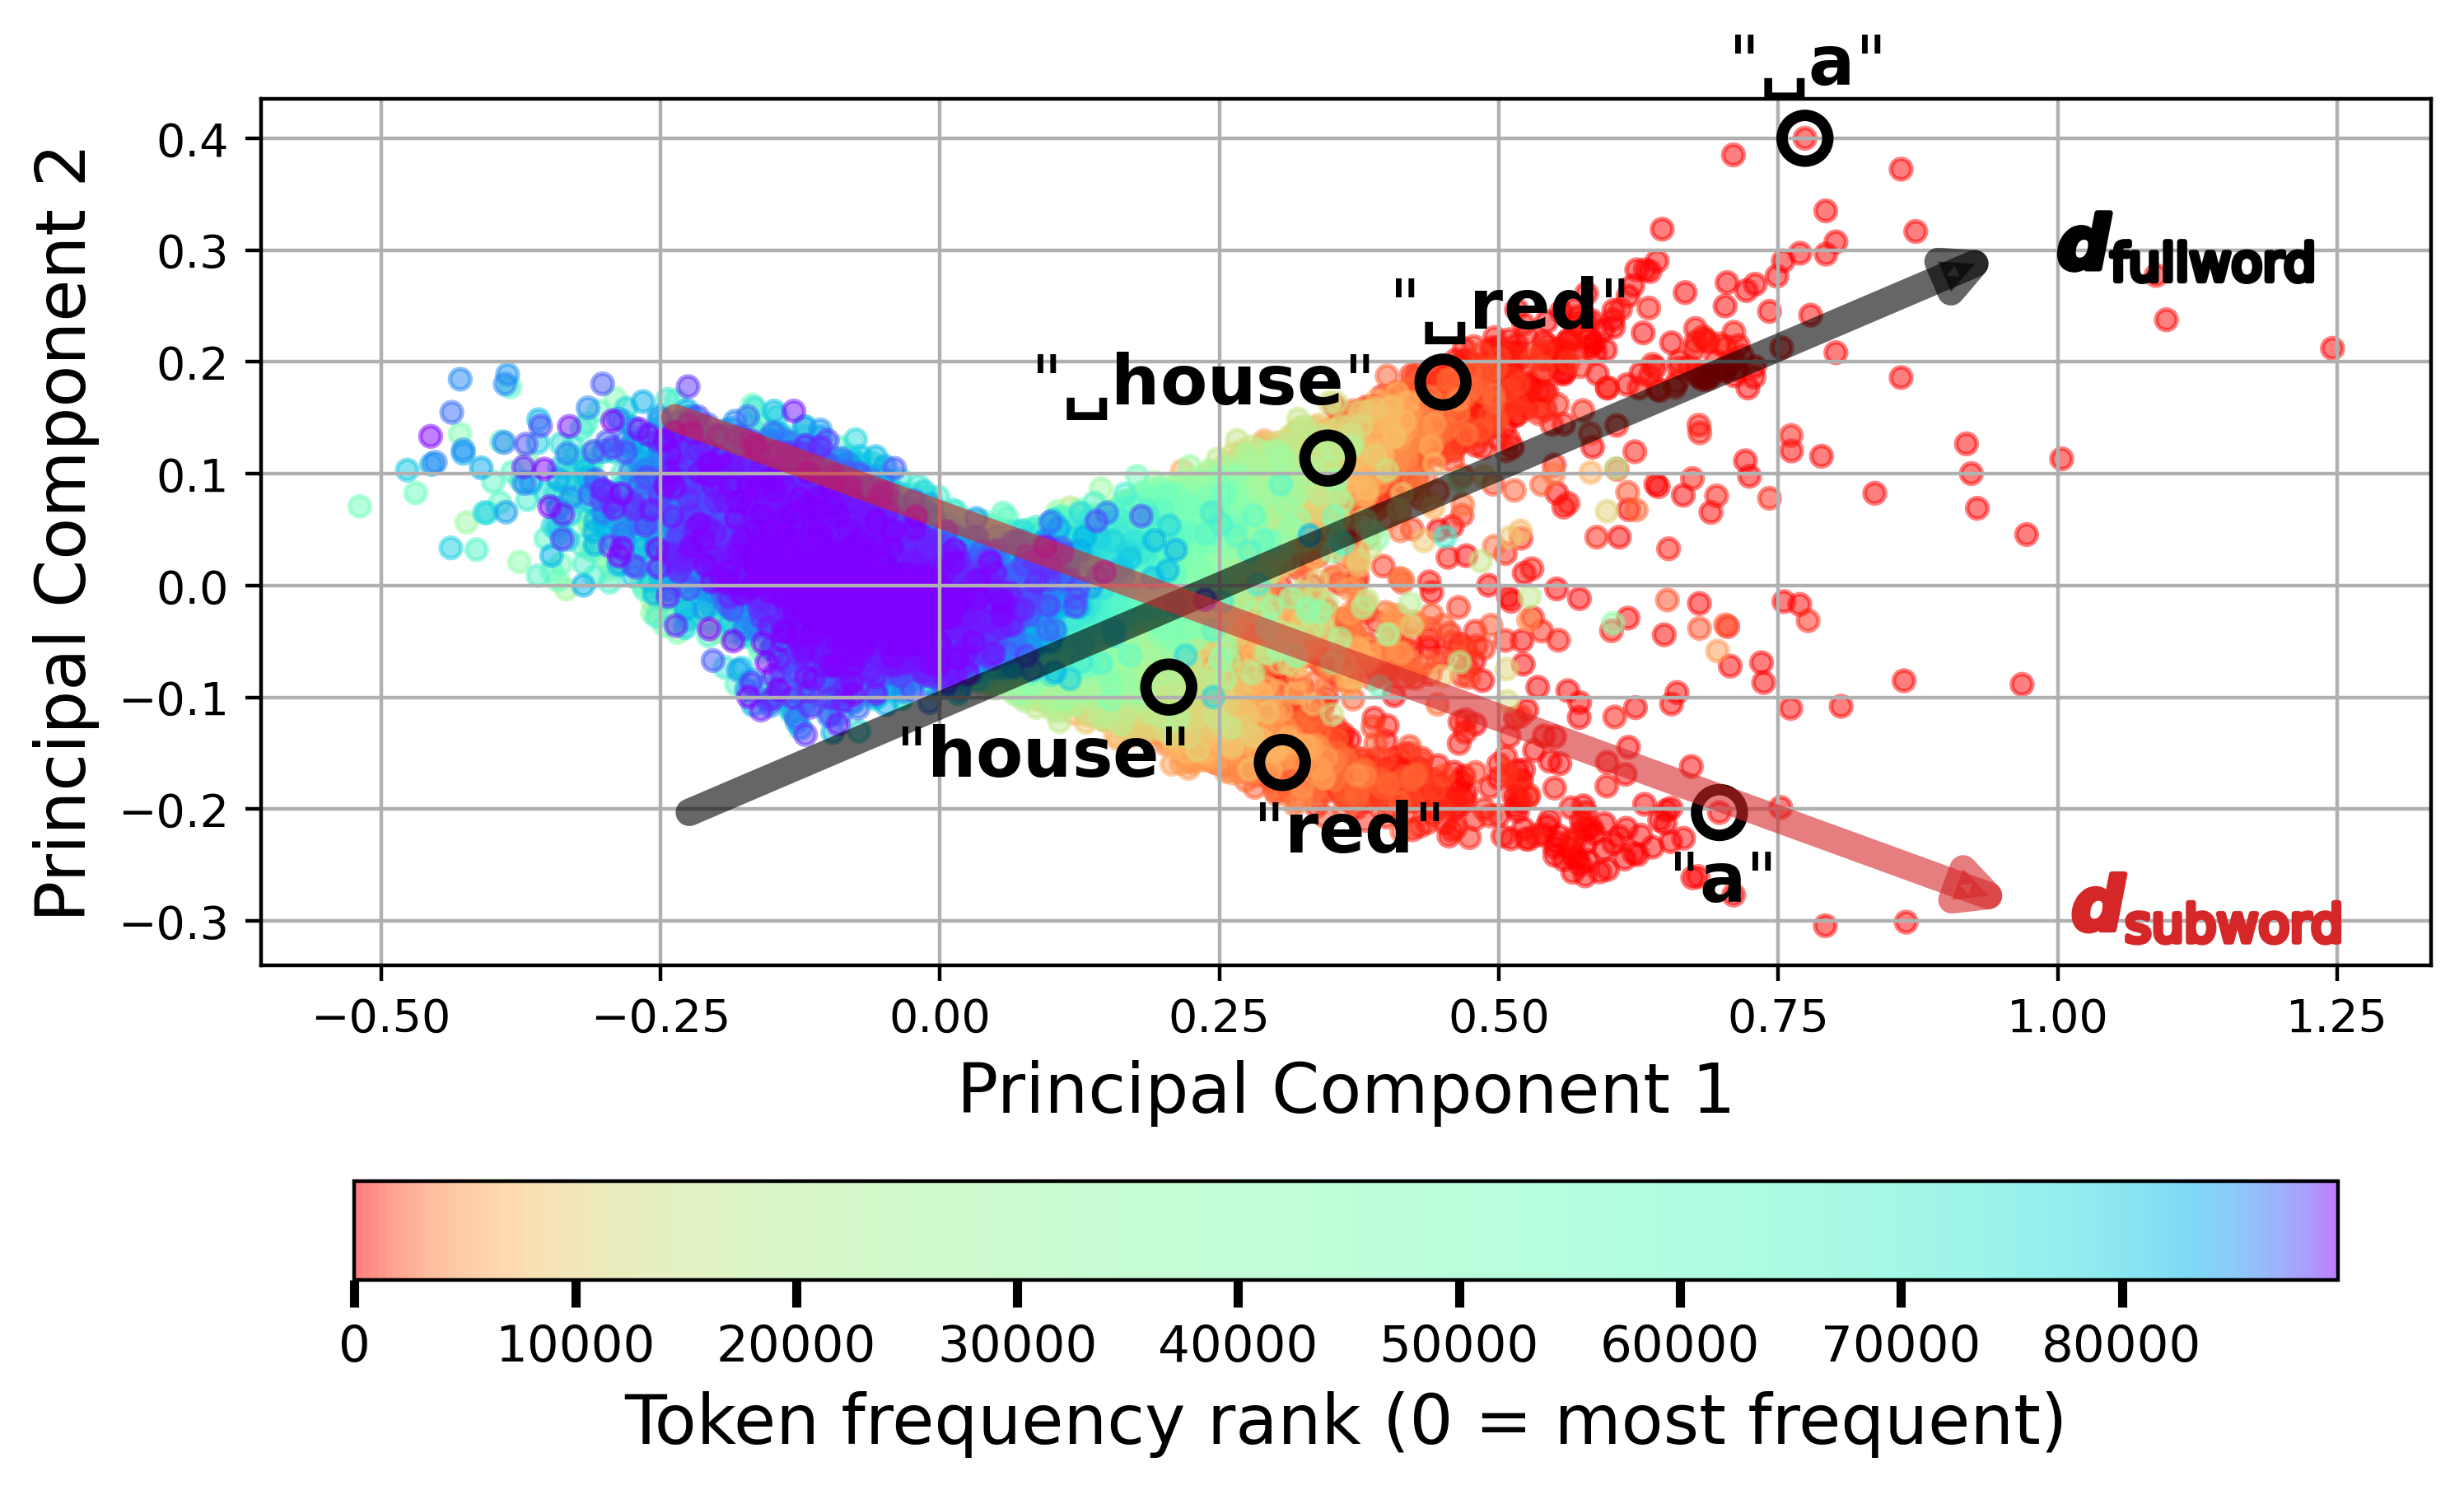

In [ ]:
# Standalone Fig. 1-style plot for one model (reuses geometry helpers above).
standalone_model = "meta-llama/Llama-3.1-8B"
ax1, ax2 = 0, 1
flip_x = False
# tag_tokens = ["a","architecture", "red", " grand", " The"]
tag_tokens = ["red","house", "a", " red", " a", " house"]


geometry = load_or_compute_grid_geometry(standalone_model)
coordinates = np.asarray(geometry["coordinates"])
rank_fraction = np.asarray(geometry["rank_fraction"])
priors = geometry["priors"]

# Draw most frequent first (bottom), matching fig1_dipole_geometry.
# Use integer ranks 0..N-1 (not normalized to [0, 1]).
order = np.argsort(rank_fraction)
coords_plot = coordinates[order]
ranks_plot = np.arange(coords_plot.shape[0], dtype=np.int64)

import matplotlib as mpl
_tan_k = 2.7
_p = np.linspace(0.0, 1.0, 256)
_warp = np.clip(0.5 + 0.5 * np.tan(_tan_k * (_p - 0.5)) / np.tan(_tan_k / 2), 0.0, 1.0)
freq_cmap = mpl.colors.ListedColormap(plt.get_cmap("rainbow_r")(_warp))

fig, ax = plt.subplots(figsize=(8.5, 8.5), dpi=400)
sc = ax.scatter(
    coords_plot[:, ax1],
    coords_plot[:, ax2],
    s=20,
    marker="o",
    c=ranks_plot,
    cmap=freq_cmap,
    alpha=0.5,
    vmin=0,
    vmax=max(ranks_plot[-1], 1),
)
cbar = fig.colorbar(
    sc,
    ax=ax,
    orientation="horizontal",
    location="bottom",
    pad=0.1,
    fraction=0.046,
)
cbar.set_label("Token frequency rank (0 = most frequent)", fontsize=15)
cbar.ax.tick_params(labelsize=11, width=2, length=6)

# Optional token callouts: project from cached W_out into the same PC plane
# used by load_or_compute_grid_geometry (re-fit a light local basis via d_hat).
# Simpler path: decode highlights only if we can map ids into the plotted cloud
# by recomputing projections for those ids from W_out + stored geometry basis.
# Here we reload W_out and rebuild the same mean/basis used for this cache.
w_out_path, tag = resolve_w_out_path(standalone_model)
w_out_memmap = np.load(w_out_path, mmap_mode="r")
tokenizer = AutoTokenizer.from_pretrained(standalone_model, trust_remote_code=True)

# Recover orientation direction from the first prior's ambient vector via
# re-fitting under the active token_mode (cheap relative to PCA sample).
probabilities = token_probabilities(tokenizer, w_out_memmap.shape[0])
space_mask = leading_space_mask(tokenizer, w_out_memmap.shape[0])
w_out_fit = np.asarray(w_out_memmap, dtype=np.float32)
if token_mode == "both":
    orient_dir = fit_d_prior(w_out_fit, probabilities)
elif token_mode == "all":
    orient_dir = fit_d_prior(w_out_fit, probabilities)
else:
    orient_dir = fit_d_prior(
        w_out_fit,
        restrict_probs_by_token_mode(probabilities, space_mask, token_mode),
    )
mean = exact_embedding_mean(w_out_memmap)
basis = sampled_pca_basis(
    w_out_memmap, mean, orient_dir, pca_sample_size, pca_random_seed
)
del w_out_fit

def _tag_label_from_token_id(tok_id):
    """Quoted label; leading whitespace shown as a visible open-box ␣.

    Returns (label, has_leading_space).
    """
    decoded = tokenizer.decode([int(tok_id)], skip_special_tokens=False)
    has_leading_space = bool(decoded) and decoded[0].isspace()
    body = decoded[1:] if has_leading_space else decoded
    # Escape mathtext-special characters in the token body.
    for old, new in (
        ("\\", "\\backslash "),
        ("_", "\\_"),
        ("%", "\\%"),
        ("&", "\\&"),
        ("#", "\\#"),
        ("$", "\\$"),
        ("{", "\\{"),
        ("}", "\\}"),
    ):
        body = body.replace(old, new)
    if has_leading_space:
        # ␣ makes the leading space visible inside mathtext.
        return rf'"$\mathbf{{␣{body}}}$"', True
    return rf'"$\mathbf{{{body}}}$"', False


for token in tag_tokens:
    enc = tokenizer.encode(token, add_special_tokens=False)
    if not enc:
        continue
    tok_id = enc[0]
    if tok_id is None or tok_id < 0 or tok_id >= w_out_memmap.shape[0]:
        continue
    row = np.asarray(w_out_memmap[tok_id], dtype=np.float32) - mean
    coord = row @ basis
    ax.scatter(
        coord[ax1], coord[ax2],
        s=100, facecolors="none", edgecolors="k",
        marker="o", zorder=5, linewidths=2.5,
    )
    label, has_leading_space = _tag_label_from_token_id(tok_id)
    # Leading-space tokens above the marker; bare subwords below — avoids
    # collisions for pairs like "␣red" / "red".
    if has_leading_space:
        x_off, va = 0, "bottom"
        y_off = 8
    else:
        x_off, va = 0, "top"
        y_off = -8
    # Nudge crowded mid-cloud tags horizontally.
    body = tokenizer.decode([int(tok_id)], skip_special_tokens=False).lstrip().lower()
    if body == "house":
        x_off = -28
    elif body == "red":
        x_off = 14
    txt = ax.annotate(
        label,
        (coord[ax1], coord[ax2]),
        textcoords="offset points",
        xytext=(x_off, y_off),
        fontsize=15,
        zorder=6,
        ha="center",
        va=va,
    )
    txt.set_clip_on(True)

# Fig. 1-style centered arrows (length = 2/3 of the x-range).
xlim = ax.get_xlim()
ylim = ax.get_ylim()
cx = 0.5 * (xlim[0] + xlim[1])
cy = 0.5 * (ylim[0] + ylim[1])
arrow_len = (2.0 / 3.0) * (xlim[1] - xlim[0])
import matplotlib.patheffects as patheffects

prior_tip_labels = {
    # \boldsymbol = bold italic; subscripts stay upright via \mathrm.
    "full word": r"$\boldsymbol{d}_{\mathrm{fullword}}$",
    "sub-word": r"$\boldsymbol{d}_{\mathrm{subword}}$",
}
for prior in priors:
    d_xy = np.asarray(prior["xy"], dtype=np.float64)
    d_xy = np.array([d_xy[ax1], d_xy[ax2]], dtype=np.float64)
    d_len = float(np.linalg.norm(d_xy))
    if d_len <= 0:
        continue
    vec = d_xy / d_len * arrow_len
    # Nudge the sub-word arrow down slightly so the two arrows separate.
    y_shift = -0.15 * (ylim[1] - ylim[0]) if prior["label"] == "sub-word" else 0.0
    start = (cx - 0.5 * vec[0], cy - 0.5 * vec[1] + y_shift)
    end = (cx + 0.5 * vec[0], cy + 0.5 * vec[1] + y_shift)
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(
            arrowstyle="-|>",
            color=prior["color"],
            lw=6,
            mutation_scale=18,
            alpha=0.6,
        ),
        zorder=7,
    )
    tip_label = prior_tip_labels.get(prior["label"])
    if tip_label is not None:
        # Screen-right of the tip (independent of flip_x / arrow direction).
        tip_text = ax.annotate(
            tip_label,
            xy=end,
            xytext=(10, 0),
            textcoords="offset points",
            color=prior["color"],
            fontsize=16,
            fontweight="bold",
            ha="left",
            va="center",
            zorder=8,
        )
        # Mathtext ignores fontweight; stroke the glyphs for a heavier bold.
        tip_text.set_path_effects(
            [patheffects.withStroke(linewidth=1.2, foreground=prior["color"])]
        )
ax.set_xlim(xlim)
ax.set_ylim(ylim)

ax.set_xlabel(f"Principal Component {ax1 + 1}", fontsize=15)
ax.set_ylabel(f"Principal Component {ax2 + 1}", fontsize=15)
ax.grid(True)
ax.set_aspect("equal", adjustable="box")
if flip_x:
    ax.invert_xaxis()

if token_mode == "both":
    import matplotlib.lines as mlines
    handles = [
        mlines.Line2D([], [], color="black", lw=3.0, marker=">", markersize=9,
                      markevery=[-1], alpha=0.75),
        mlines.Line2D([], [], color="C3", lw=3.0, marker=">", markersize=9,
                      markevery=[-1], alpha=0.75),
    ]
    # ax.legend(
    #     handles,
    #     [
    #         r"full word $\hat{\boldsymbol{d}}_{\mathrm{prior}}$",
    #         r"sub-word $\hat{\boldsymbol{d}}_{\mathrm{prior}}$",
    #     ],
    #     loc="upper right",
    #     frameon=False,
    #     fontsize=12,
    # )

# title = (
#     f"{grid_model_label(standalone_model)}  |  coverage={vocab_coverage:g}  |  "
#     f"{corpus_choice if p_zipf_from_pile else 'Zipf'}  |  token_mode={token_mode}"
# )
# ax.set_title(title, fontsize=13, fontweight="bold")

export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
coverage_tag = f"{vocab_coverage:g}".replace(".", "p")
mode_tag = "both_orientall" if token_mode == "both" else token_mode.replace("_", "")
export_path = export_dir / (
    f"dual_prior_{grid_model_tag(standalone_model)}"
    f"_coverage{coverage_tag}_mode{mode_tag}.png"
)
fig.savefig(export_path, bbox_inches="tight")
print(f"fig saved at {export_path}")
plt.show()


In [ ]:
tag_tokens = ["a","architecture", "red", " grand", " The"]
tag_tokens = ["grand","architecture", "the", " grand", " the"]
for token in tag_tokens:
    tok_id = tokenizer.encode(token, add_special_tokens=False)[0]
    print(tok_id)

53766
81519
1820
6800
279
